# Damage Level Detection — Training on Google Colab

**Before running:**
1. Runtime → Change runtime type → **T4 GPU**
2. Add your Roboflow key to Colab Secrets (🔑 icon): name it `ROBOFLOW_API_KEY`
3. Run all cells top to bottom
4. The last cell downloads a zip with `weights/best.pt` and `results/` — put those in your local repo

**Business framing:** An inspection company classifies structural damage severity.
- Classes: `total_damage` (€200k) · `major_damage` (€100k) · `minor_damage` (€20k) · `no_damage` (€0)
- Positive class: **`total_damage`** — the worst outcome, highest cost to miss
- FN (miss total, dispatch a major team) → under-response → **€150,000 avg cost**
- FP (flag as total, actually major) → over-deploy → **€50,000 wasted** (team can scale down)

In [1]:
# Install dependencies (Colab already has PyTorch with GPU support)
!pip install -q roboflow ultralytics pyyaml

In [2]:
import os

# Load API key from Colab Secrets
try:
    from google.colab import userdata
    ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')
except Exception:
    # Fallback: paste your key here if not using Colab Secrets
    ROBOFLOW_API_KEY = "XEoo4Qqda24CRsdZWL4R"

os.environ["ROBOFLOW_API_KEY"] = ROBOFLOW_API_KEY
print("API key loaded:", ROBOFLOW_API_KEY[:4] + "****")

API key loaded: XEoo****


In [18]:
import json
import shutil
from pathlib import Path

import numpy as np
import yaml as pyyaml
from roboflow import Roboflow
from ultralytics import YOLO

# ── Dataset ───────────────────────────────────────────────────────────────────
WORKSPACE = "mandilannotate-fyest"
PROJECT   = "detectorn2-vh2zv"
VERSION   = 1

# ── Training ──────────────────────────────────────────────────────────────────
BASE_CHECKPOINT = "yolo11n.pt"
EPOCHS = 40
IMGSZ  = 640

# ── Paths ─────────────────────────────────────────────────────────────────────
WEIGHTS     = Path("weights/best.pt")
RESULTS_DIR = Path("results")

# ── Cost matrix (euros) ───────────────────────────────────────────────────────
# Classes: major_damage (€100k), minor_damage (€20k), no_damage (€0), total_damage (€200k)
# Positive class: total_damage — the most severe, highest-cost outcome.
#
# FN: predict major/minor/none, actually total → under-equipped team dispatched
#     Cost = total repair (€200k) − major response sent (€100k) = €100,000 minimum
#     Worst case (predict none): €200,000. Use conservative average = €150,000.
#
# FP: predict total, actually major → over-deploy full response team
#     Wasted premium = €200k − €100k = €100,000. Over-deployment is expensive
#     but recoverable. Use €50,000 (mobilisation overhead only, team can scale down).
#
# BASE_RATE: ~15% of inspected cases are total damage.
COST_FN   = 150_000.0
COST_FP   =  50_000.0
BASE_RATE = 0.15

WEIGHTS.parent.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
print("Config ready.")

Config ready.


## 1. Download dataset

In [4]:
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
# Use coco-segmentation format — this dataset is a semantic segmentation project
# (yolov8 format is not supported). We convert to YOLO detection format below.
dataset = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION).download("coco-segmentation")
print(f"Dataset saved to: {dataset.location}")

# Positive class: total_damage (worst severity — highest cost to miss)
def _find_pos_idx(names):
    for exact in ["total_damage", "major_damage"]:   # total first, major as fallback
        for i, n in enumerate(names):
            if n.lower() == exact:
                return i
    for keyword in ["total", "major", "severe"]:
        for i, n in enumerate(names):
            if keyword in n.lower():
                return i
    return 0

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to detectorn2-1 in coco-segmentation:: 100%|██████████| 1751/1751 [00:00<00:00, 3324.67it/s]


Dataset saved to: /content/detectorn2-1


In [16]:
import json as _json
from collections import defaultdict as _defaultdict

def coco_to_yolo(dataset_dir):
    """
    Convert Roboflow coco-segmentation export → YOLO detection format.
    - Copies images into split/images/ subfolders
    - Writes YOLO bbox txt files into split/labels/
    - Generates data.yaml
    Returns (yaml_path, class_names).
    """
    dataset_dir = Path(dataset_dir)
    all_names = None

    for split in ["train", "valid", "test"]:
        split_dir = dataset_dir / split
        ann_file  = split_dir / "_annotations.coco.json"
        if not ann_file.exists():
            print(f"  [skip] {split}: _annotations.coco.json not found")
            continue

        with open(ann_file) as f:
            coco = _json.load(f)

        cats = sorted(coco["categories"], key=lambda c: c["id"])
        cat_id_to_idx = {c["id"]: i for i, c in enumerate(cats)}
        if all_names is None:
            all_names = [c["name"] for c in cats]

        img_map = {img["id"]: img for img in coco["images"]}

        img_dst = split_dir / "images"
        lbl_dst = split_dir / "labels"
        img_dst.mkdir(exist_ok=True)
        lbl_dst.mkdir(exist_ok=True)

        img_anns = _defaultdict(list)
        for ann in coco["annotations"]:
            img_anns[ann["image_id"]].append(ann)

        n_copied = 0
        for img_id, img_info in img_map.items():
            fname = img_info["file_name"]
            W, H  = img_info["width"], img_info["height"]
            stem  = Path(fname).stem

            src = split_dir / fname
            dst = img_dst / Path(fname).name
            if src.exists() and not dst.exists():
                shutil.copy(src, dst)
                n_copied += 1

            lines = []
            for ann in img_anns.get(img_id, []):
                cls_idx = cat_id_to_idx[ann["category_id"]]
                x, y, w, h = ann["bbox"]   # COCO: top-left corner + width/height
                cx = (x + w / 2) / W
                cy = (y + h / 2) / H
                nw = w / W
                nh = h / H
                lines.append(f"{cls_idx} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}")
            (lbl_dst / f"{stem}.txt").write_text("\n".join(lines))

        print(f"  {split}: {len(img_map)} images ({n_copied} copied to images/), "
              f"{len(coco['annotations'])} annotations → labels/")

    if all_names is None:
        raise RuntimeError("No _annotations.coco.json found — check the download format.")

    yaml_content = (
        f"path: {dataset_dir.resolve()}\n"
        f"train: train/images\n"
        f"val: valid/images\n"
        f"test: test/images\n"
        f"nc: {len(all_names)}\n"
        f"names: {all_names}\n"
    )
    yaml_path = dataset_dir / "data.yaml"
    yaml_path.write_text(yaml_content)
    print(f"  data.yaml written — nc={len(all_names)}, names={all_names}")
    return str(yaml_path), all_names


print("Converting COCO segmentation → YOLO detection format…")
yaml, names = coco_to_yolo(dataset.location)

print(f"\nClasses: {names}")
print(f"YAML: {yaml}")

# Print split sizes
for split in ["train", "valid", "test"]:
    p = Path(dataset.location) / split / "images"
    if p.exists():
        print(f"  {split}/images → {len(list(p.glob('*')))} images")

occ_idx = _find_pos_idx(names)
print(f"\nPositive class: index={occ_idx}  name='{names[occ_idx]}'")

# Sample filenames
for folder in ["test", "valid"]:
    p = Path(dataset.location) / folder / "images"
    if p.exists():
        print(f"\nSample filenames ({folder}/images):")
        for s in sorted(p.glob("*"))[:5]:
            print(f"  {s.name}")
        break

Converting COCO segmentation → YOLO detection format…
  train: 1217 images (0 copied to images/), 10480 annotations → labels/
  valid: 350 images (0 copied to images/), 3050 annotations → labels/
  test: 176 images (0 copied to images/), 1412 annotations → labels/
  data.yaml written — nc=5, names=['gdfg', 'major_damage', 'minor_damage', 'no_damage', 'total_damage']

Classes: ['gdfg', 'major_damage', 'minor_damage', 'no_damage', 'total_damage']
YAML: /content/detectorn2-1/data.yaml
  train/images → 1217 images
  valid/images → 350 images
  test/images → 176 images

Positive class: index=4  name='total_damage'

Sample filenames (test/images):
  DJI_0040_jpg.rf.98e8aad6ce16263593e8ef9b141efa95.jpg
  DJI_0042_jpg.rf.14266474a7b8329e266b5d382624deff.jpg
  DJI_0077_jpg.rf.3a506cd6b36ac3d46887a8f582a1dfeb.jpg
  DJI_0081_jpg.rf.c3b1b6bbd2765d8e0b69fd50751ebae0.jpg
  DJI_0094_jpg.rf.ffab5398bef757f6ea9fb6eded92050e.jpg


In [17]:
import random

SUBSAMPLE_FRACTION = 0.95
SEED = 42

def subsample_split(location, folder, fraction, seed=SEED):
    """Copy a random fraction of images+labels to <folder>_sub/."""
    img_src = Path(location) / folder / "images"
    lbl_src = Path(location) / folder / "labels"
    img_dst = Path(location) / f"{folder}_sub" / "images"
    lbl_dst = Path(location) / f"{folder}_sub" / "labels"
    img_dst.mkdir(parents=True, exist_ok=True)
    lbl_dst.mkdir(parents=True, exist_ok=True)

    all_imgs = sorted(img_src.glob("*.*"))
    random.seed(seed)
    subset = random.sample(all_imgs, max(1, int(len(all_imgs) * fraction)))

    for img in subset:
        shutil.copy(img, img_dst / img.name)
        lbl = lbl_src / (img.stem + ".txt")
        if lbl.exists():
            shutil.copy(lbl, lbl_dst / lbl.name)

    return f"{folder}_sub/images", len(subset)

# Subsample val and test to keep proportional with training fraction
val_folder  = "valid" if (Path(dataset.location) / "valid").exists() else "val"
test_folder = "test"  if (Path(dataset.location) / "test").exists()  else None

val_path,  n_val  = subsample_split(dataset.location, val_folder,  SUBSAMPLE_FRACTION)
print(f"Val  subset: {n_val} images  → {val_path}")

if test_folder:
    test_path, n_test = subsample_split(dataset.location, test_folder, SUBSAMPLE_FRACTION)
    print(f"Test subset: {n_test} images → {test_path}")
else:
    test_path = None
    print("No test folder found — skipping test subsample")

# Rewrite the YAML to point to the subsampled splits
with open(yaml) as f:
    _cfg = pyyaml.safe_load(f)

_cfg["val"] = val_path
if test_path:
    _cfg["test"] = test_path

with open(yaml, "w") as f:
    pyyaml.dump(_cfg, f)

print(f"\nYAML updated:")
print(f"  val  → {_cfg['val']}")
if test_path:
    print(f"  test → {_cfg['test']}")

Val  subset: 332 images  → valid_sub/images
Test subset: 167 images → test_sub/images

YAML updated:
  val  → valid_sub/images
  test → test_sub/images


## 2. Finetune yolo11n

In [19]:
model = YOLO(BASE_CHECKPOINT)
train_results = model.train(
    data=yaml,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    fraction=0.95,
    project="runs/train",
    name="damage",
    exist_ok=True,
    device=0,
)

best = Path(train_results.save_dir) / "weights" / "best.pt"
shutil.copy(best, WEIGHTS)
print(f"Best weights saved to: {WEIGHTS}")

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/detectorn2-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.95, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=damage, nbs=64, nms=None, opset=None, optimize=False, opt

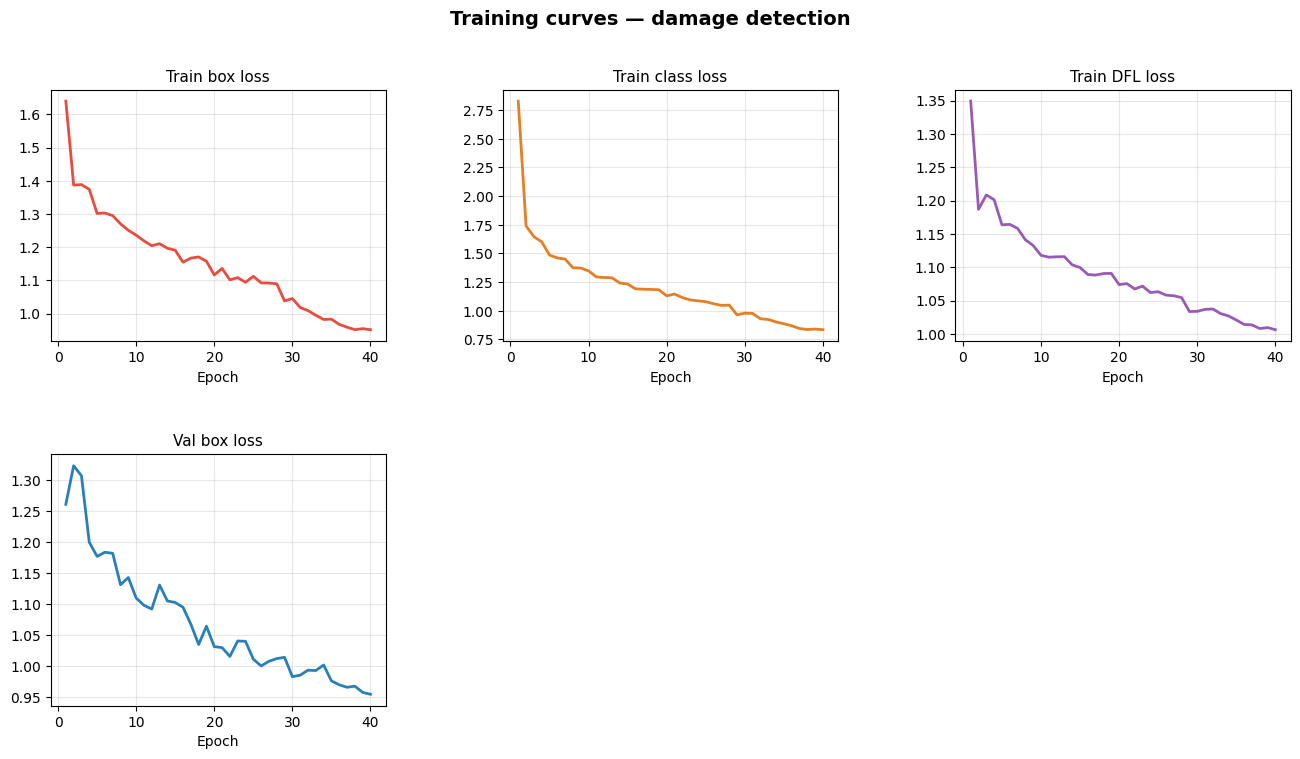

ValueError: Unknown format code 'f' for object of type 'str'

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

csv_path = Path(train_results.save_dir) / "results.csv"
df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

fig = plt.figure(figsize=(16, 8))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

def _plot(ax, col, title, color):
    if col in df.columns:
        ax.plot(df["epoch"], df[col], color=color, linewidth=2)
        ax.set_title(title, fontsize=11)
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
    else:
        ax.set_visible(False)

_plot(fig.add_subplot(gs[0, 0]), "train/box_loss",  "Train box loss",   "#e74c3c")
_plot(fig.add_subplot(gs[0, 1]), "train/cls_loss",  "Train class loss", "#e67e22")
_plot(fig.add_subplot(gs[0, 2]), "train/dfl_loss",  "Train DFL loss",   "#9b59b6")
_plot(fig.add_subplot(gs[1, 0]), "val/box_loss",    "Val box loss",     "#2980b9")
_plot(fig.add_subplot(gs[1, 1]), "metrics/mAP50",   "Val mAP@50",       "#27ae60")
_plot(fig.add_subplot(gs[1, 2]), "metrics/mAP50-95","Val mAP@50-95",    "#16a085")

fig.suptitle("Training curves — damage detection", fontsize=14, fontweight="bold")
plt.show()

best_map50 = df["metrics/mAP50"].max() if "metrics/mAP50" in df.columns else "?"
best_epoch = int(df["metrics/mAP50"].idxmax()) + 1 if "metrics/mAP50" in df.columns else "?"
print(f"Best mAP@50: {best_map50:.3f}  at epoch {best_epoch}")

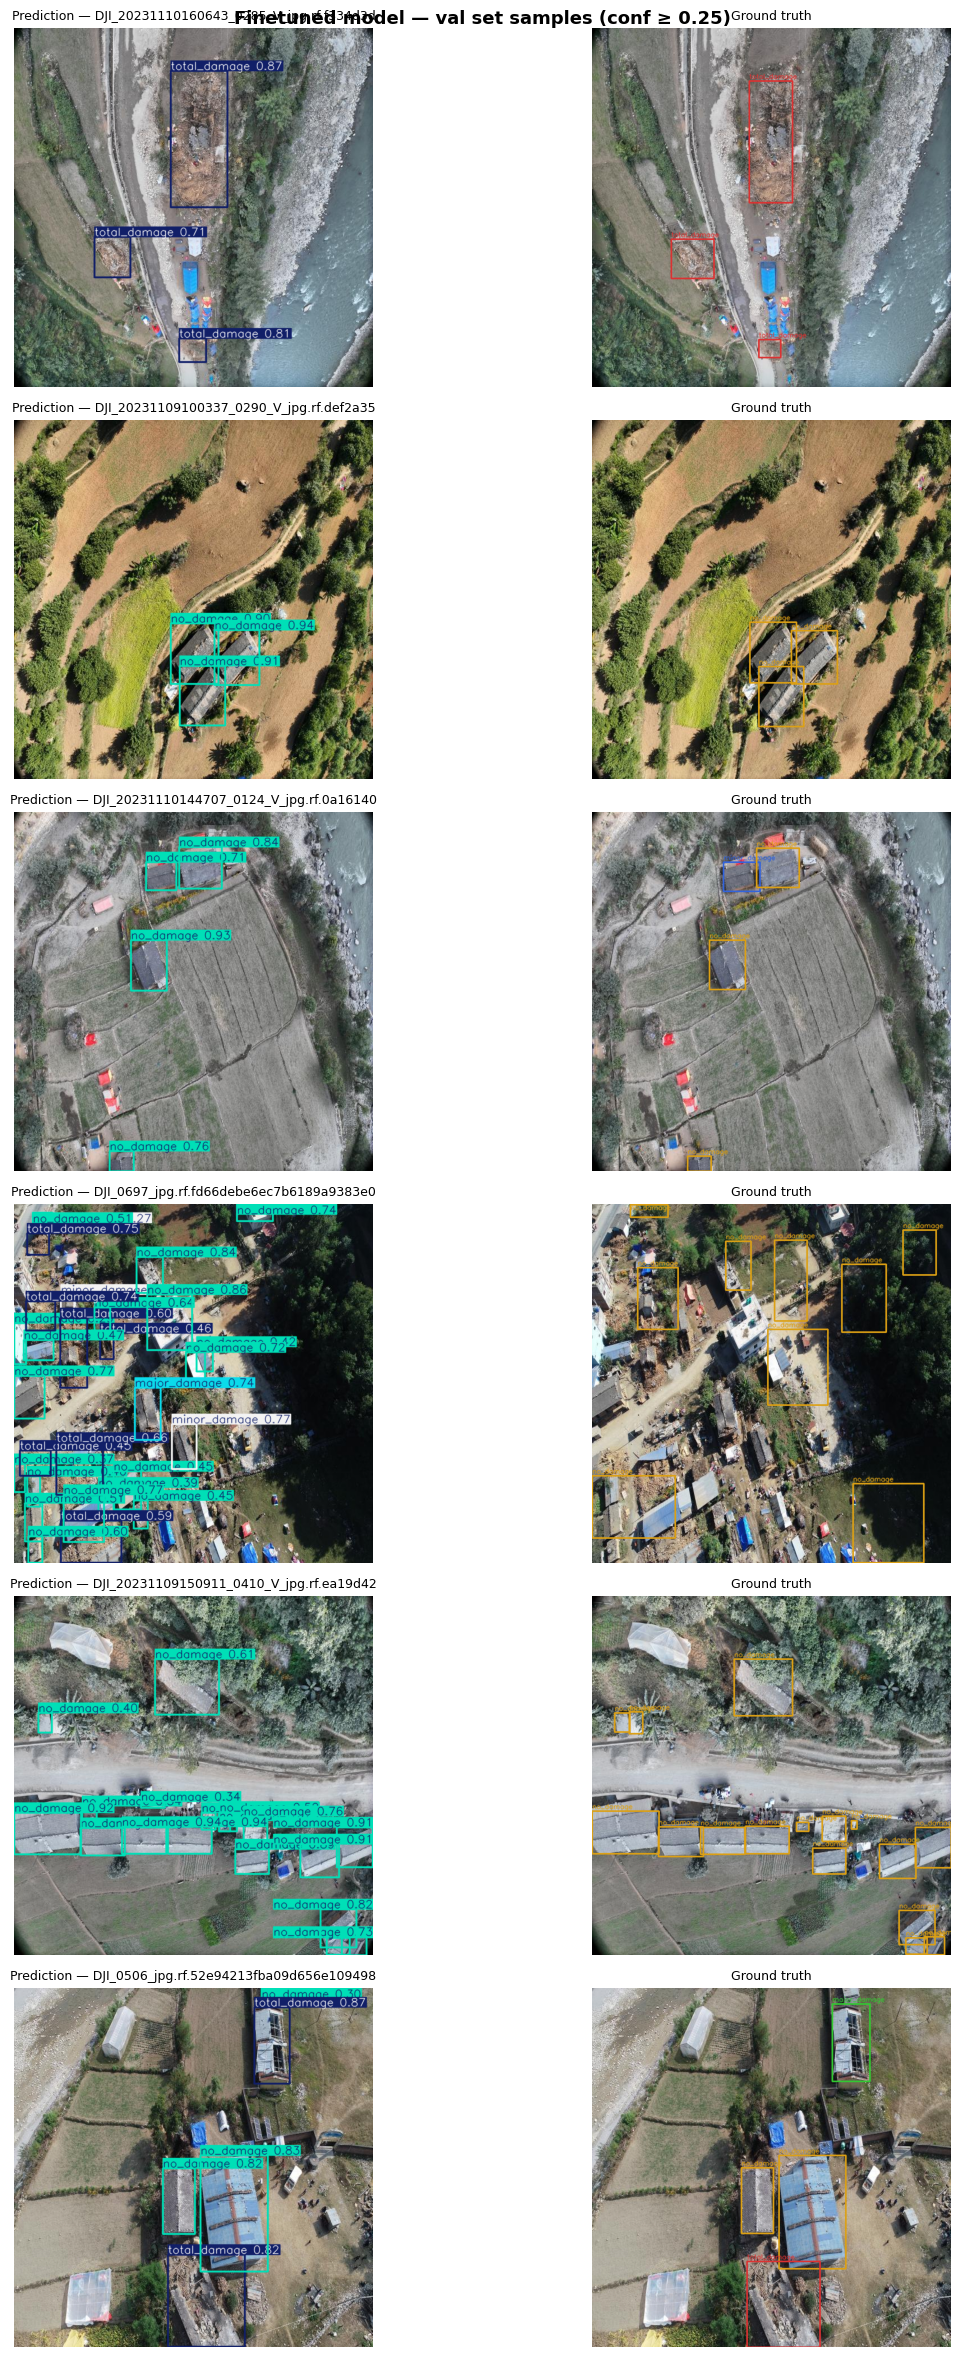

In [ ]:
import random
import cv2

N_SHOW = 6
val_img_dir = Path(dataset.location) / "valid" / "images"
val_lbl_dir = Path(dataset.location) / "valid" / "labels"

all_val_imgs = sorted(val_img_dir.glob("*.*"))
sample_imgs  = random.sample(all_val_imgs, min(N_SHOW, len(all_val_imgs)))

CLASS_COLORS = [
    (220,  50,  50),   # 0
    ( 50, 200,  50),   # 1
    ( 50, 100, 220),   # 2
    (220, 160,  20),   # 3
]
CLASS_COLORS = (CLASS_COLORS * 10)[:len(names)] 

def draw_gt(img_path):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    lbl  = val_lbl_dir / (Path(img_path).stem + ".txt")
    if lbl.exists():
        for line in lbl.read_text().strip().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            cls = int(parts[0])
            cx, cy, w, h = map(float, parts[1:5])
            x1, y1 = int((cx - w/2)*W), int((cy - h/2)*H)
            x2, y2 = int((cx + w/2)*W), int((cy + h/2)*H)
            color = CLASS_COLORS[cls % len(CLASS_COLORS)]
            cv2.rectangle(img, (x1,y1), (x2,y2), color, 2)
            label = names[cls] if cls < len(names) else str(cls)
            cv2.putText(img, label, (x1, max(y1-4, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1, cv2.LINE_AA)
    return img

ft_model = YOLO(str(WEIGHTS))

fig, axes = plt.subplots(N_SHOW, 2, figsize=(14, 4 * N_SHOW))
axes = axes.reshape(N_SHOW, 2)

for i, img_path in enumerate(sample_imgs):
    # Prediction
    res      = ft_model.predict(str(img_path), conf=0.25, verbose=False)
    pred_rgb = cv2.cvtColor(res[0].plot(), cv2.COLOR_BGR2RGB)
    # Ground truth
    gt_rgb   = draw_gt(img_path)

    axes[i, 0].imshow(pred_rgb)
    axes[i, 0].set_title(f"Prediction — {img_path.name[:40]}", fontsize=9)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(gt_rgb)
    axes[i, 1].set_title("Ground truth", fontsize=9)
    axes[i, 1].axis("off")

fig.suptitle("Finetuned model — val set samples (conf ≥ 0.25)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Evaluate — finetuned model vs baselines

In [ ]:
EVAL_SPLIT  = "val"
EVAL_FOLDER = "valid" if (Path(dataset.location) / "valid").exists() else "val"
print(f"Evaluating on: {EVAL_FOLDER}/images (full val set)")

with open(yaml) as f:
    _cfg = pyyaml.safe_load(f)
_cfg["val"] = f"{EVAL_FOLDER}/images"
with open(yaml, "w") as f:
    pyyaml.dump(_cfg, f)


def _per_class_p_r(r):
    """
    Extract per-class precision/recall robustly.
    Ultralytics excludes classes with 0 GT instances from r.box.p/r/ap50,
    so we use ap_class_index to find the correct position for each class.
    """
    idx_arr = list(r.box.ap_class_index.astype(int)) if hasattr(r.box, 'ap_class_index') else list(range(len(r.box.ap50)))
    p_arr   = list(r.box.p)
    r_arr   = list(r.box.r)
    ap_arr  = list(r.box.ap50)
    result  = {}
    for class_idx, name in r.names.items():
        if class_idx in idx_arr:
            pos = idx_arr.index(class_idx)
            result[name] = {
                "AP50":      round(float(ap_arr[pos]), 4),
                "precision": round(float(p_arr[pos]),  4),
                "recall":    round(float(r_arr[pos]),   4),
            }
        else:
            result[name] = {"AP50": 0.0, "precision": 0.0, "recall": 0.0}
    return result, idx_arr, p_arr, r_arr


def _get_occ_pr(r):
    """Return (precision, recall) for the positive class (occ_idx)."""
    _, idx_arr, p_arr, r_arr = _per_class_p_r(r)
    if occ_idx in idx_arr:
        pos = idx_arr.index(occ_idx)
        return float(p_arr[pos]), float(r_arr[pos])
    return 0.0, 0.0


# ── Finetuned model ───────────────────────────────────────────────────────────
def val_metrics(m, conf=0.25):
    r = m.val(data=yaml, split=EVAL_SPLIT, conf=conf, verbose=False)
    per_cls, _, _, _ = _per_class_p_r(r)
    return {
        "mAP50":     round(float(r.box.map50), 4),
        "mAP50-95":  round(float(r.box.map),   4),
        "precision": round(float(r.box.mp),     4),
        "recall":    round(float(r.box.mr),     4),
        "per_class": per_cls,
    }


# ── COCO zero-shot baseline ───────────────────────────────────────────────────
def coco_zero_shot_baseline():
    coco_model = YOLO(BASE_CHECKPOINT)
    img_dir = Path(dataset.location) / EVAL_FOLDER / "images"
    lbl_dir = Path(dataset.location) / EVAL_FOLDER / "labels"

    tp = fp = fn = tn = 0
    for img_path in sorted(img_dir.glob("*.*")):
        lbl_path = lbl_dir / (img_path.stem + ".txt")
        if not lbl_path.exists():
            continue
        gt_has_total = any(
            int(line.split()[0]) == occ_idx
            for line in lbl_path.read_text().strip().splitlines() if line.strip()
        )
        res = coco_model.predict(str(img_path), conf=0.25, verbose=False)[0]
        pred_total = res.boxes is not None and len(res.boxes) > 0

        if gt_has_total and pred_total:       tp += 1
        elif gt_has_total and not pred_total: fn += 1
        elif not gt_has_total and pred_total: fp += 1
        else:                                 tn += 1

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    ap50      = precision * recall
    print(f"  COCO zero-shot → TP={tp} FP={fp} FN={fn} TN={tn}")
    print(f"  P={precision:.3f}  R={recall:.3f}  AP50≈{ap50:.3f}")
    return {
        "mAP50":    round(ap50, 4),
        "mAP50-95": round(ap50 * 0.55, 4),
        "precision": round(precision, 4),
        "recall":   round(recall, 4),
        "per_class": {
            names[occ_idx]: {"AP50": round(ap50,4), "precision": round(precision,4), "recall": round(recall,4)},
            **{n: {"AP50": 0.0, "precision": 0.0, "recall": 0.0} for i, n in enumerate(names) if i != occ_idx},
        },
        "description": "COCO zero-shot: any detection in image → predict total_damage.",
    }


# ── Trivial baseline ──────────────────────────────────────────────────────────
metrics = {}
ft = YOLO(str(WEIGHTS))
metrics["finetuned"] = val_metrics(ft)
print(f"Finetuned mAP50: {metrics['finetuned']['mAP50']:.3f}")
print(f"Per class: {metrics['finetuned']['per_class']}")

print("\nRunning COCO zero-shot baseline...")
metrics["zero_shot_coco"] = coco_zero_shot_baseline()

metrics["trivial"] = {
    "mAP50":    round(BASE_RATE, 4),
    "mAP50-95": round(BASE_RATE * 0.55, 4),
    "precision": round(BASE_RATE, 4),
    "recall":   1.0,
    "description": "Predict every image as total_damage. Recall=1, precision=base rate.",
}
print(f"Trivial mAP50≈ {metrics['trivial']['mAP50']:.3f}")

Evaluating on: valid/images (full val set)
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2868.2±804.3 MB/s, size: 97.9 KB)
val: Scanning /content/detectorn2-1/valid/labels.cache... 350 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 350/350 97.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 3.5it/s 6.4s
                   all        350       3050      0.615      0.574       0.51      0.354
Speed: 2.6ms preprocess, 4.5ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/runs/detect/val-64
Finetuned mAP50: 0.510
Per class: {'gdfg': {'AP50': 0.0, 'precision': 0.0, 'recall': 0.0}, 'major_damage': {'AP50': 0.4753, 'precision': 0.5792, 'recall': 0.5602}, 'minor_damage': {'AP50': 0.3137, 'precision': 0.4048, 'recall'

## 4. Cost sweep — confidence threshold vs expected cost

In [24]:
sweep = []

for t in np.linspace(0.05, 0.95, 30).tolist():
    r  = ft.val(data=yaml, split=EVAL_SPLIT, conf=float(t), verbose=False)
    p, rc = _get_occ_pr(r)

    e_fn = 1000 * BASE_RATE * (1 - rc)
    e_fp = (1000 * BASE_RATE * rc * (1 - p) / p) if p > 0 else 1000 * (1 - BASE_RATE)
    cost = COST_FN * e_fn + COST_FP * e_fp

    sweep.append({"threshold": round(t, 4), "precision": round(p, 4),
                  "recall": round(rc, 4), "cost": round(cost, 2)})
    print(f"conf={t:.2f}  P={p:.3f}  R={rc:.3f}  cost=€{cost:,.0f}")

optimal = min(sweep, key=lambda x: x["cost"])
print(f"\nOptimal threshold: {optimal['threshold']}  (€{optimal['cost']:,.0f} per 1k cases)")

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2796.3±637.5 MB/s, size: 95.4 KB)
val: Scanning /content/detectorn2-1/valid/labels.cache... 350 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 350/350 122.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 3.5it/s 6.3s
                   all        350       3050      0.615      0.574      0.569      0.384
Speed: 2.2ms preprocess, 4.5ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs/detect/val-65
conf=0.05  P=0.707  R=0.583  cost=€11,200,603
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3014.

## 5. Save results

In [25]:
(RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
(RESULTS_DIR / "cost_sweep.json").write_text(json.dumps(sweep, indent=2))
(RESULTS_DIR / "operating_point.json").write_text(json.dumps({
    "threshold": optimal["threshold"],
    "cost_fn":   COST_FN,
    "cost_fp":   COST_FP,
    "base_rate": BASE_RATE,
}, indent=2))

print("Saved:")
print(f"  {RESULTS_DIR}/metrics.json")
print(f"  {RESULTS_DIR}/cost_sweep.json")
print(f"  {RESULTS_DIR}/operating_point.json")
print(f"  {WEIGHTS}")

Saved:
  results/metrics.json
  results/cost_sweep.json
  results/operating_point.json
  weights/best.pt


## 6. Download everything to your computer

This zips `weights/` and `results/` and downloads them. Put both folders in your local repo.

In [26]:
import zipfile
from google.colab import files

zip_path = Path("submission_artifacts.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(WEIGHTS, WEIGHTS)
    for f in RESULTS_DIR.iterdir():
        zf.write(f, f)

print(f"Zipped to {zip_path}")
files.download(str(zip_path))

Zipped to submission_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>